# ContractIQ: AI-Based Legal Contract Clause Detection and Risk Analysis

## 1. Project Introduction
Legal contracts contain important clauses about payment, termination, confidentiality, liability, renewal, and other obligations. Reading these clauses manually can take a lot of time. This project uses natural language processing and machine learning to identify possible clause categories in contract text and calculate a simple project-specific risk score.

**Disclaimer:** The system is an educational research project and not a replacement for a lawyer.


## 2. Project Objectives
* Load and understand the CUAD dataset.
* Convert the dataset into a usable NLP format.
* Explore the dataset and identify class imbalance.
* Preprocess legal text carefully.
* Convert text into numerical TF-IDF features.
* Train Logistic Regression, Linear SVM, and Naive Bayes.
* Compare the models using suitable multi-label metrics.
* Evaluate performance for every clause.
* Use a real legal text example for inference.
* Detect clauses in the example.
* Calculate a transparent heuristic risk score.
* Save the best model and preprocessing objects.


## 3. Dataset Description
The dataset filename is `CUAD_combined.csv`. 
CUAD means Contract Understanding Atticus Dataset.
The dataset contains legal contract text and clause annotations. 
The dataset may contain many clause columns. Each clause column represents whether a clause is present. 
The dataset is used for educational and research purposes.
The dataset may be imbalanced because some clauses occur more often than others.


## 4. Import Libraries

In [1]:
import os
import re
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from itertools import combinations

from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    hamming_loss,
    accuracy_score,
    classification_report
)

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
np.random.seed(42)


## 5. Load Dataset
We load the dataset so that we can inspect the contract text and clause annotations before preparing the data for machine learning.


In [2]:
DATA_PATH = "CUAD_combined.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"Error: {DATA_PATH} not found. Please ensure the dataset is in the notebook directory.")

df = pd.read_csv(DATA_PATH)
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nData Types:")
print(df.dtypes.head(10)) # showing first 10 for brevity


Dataset Shape: (510, 84)

First 5 rows:


,source_file,filename,document_name,document_name_answer,parties,parties_answer,agreement_date,agreement_date_answer,effective_date,effective_date_answer,...,liquidated_damages,liquidated_damages_answer,warranty_duration,warranty_duration_answer,insurance,insurance_answer,covenant_not_to_sue,covenant_not_to_sue_answer,third_party_beneficiary,third_party_beneficiary_answer
0,CUAD_v1/master_clauses.csv,CybergyHoldingsInc_20140520_10-Q_EX-10.27_8605...,['MARKETING AFFILIATE AGREEMENT'],MARKETING AFFILIATE AGREEMENT,"['BIRCH FIRST GLOBAL INVESTMENTS INC.', 'MA', ...","Birch First Global Investments Inc. (""Company""...","['8th day of May 2014', 'May 8, 2014']",5/8/14,['This agreement shall begin upon the date of ...,NaN,...,[],No,"[""COMPANY'S SOLE AND EXCLUSIVE LIABILITY FOR T...",Yes,[],No,[],No,[],No
1,CUAD_v1/master_clauses.csv,EuromediaHoldingsCorp_20070215_10SB12G_EX-10.B...,['VIDEO-ON-DEMAND CONTENT LICENSE AGREEMENT'],VIDEO-ON-DEMAND CONTENT LICENSE AGREEMENT,"['EuroMedia Holdings Corp.', 'Rogers', 'Rogers...","Rogers Cable Communications Inc. (""Rogers""); E...","['July 11 , 2006']",7/11/06,"['July 11 , 2006']",7/11/06,...,[],No,[],No,[],No,[],No,[],No
2,CUAD_v1/master_clauses.csv,FulucaiProductionsLtd_20131223_10-Q_EX-10.9_83...,['CONTENT DISTRIBUTION AND LICENSE AGREEMENT'],CONTENT DISTRIBUTION AND LICENSE AGREEMENT,"['Producer', 'Fulucai Productions Ltd.', 'Conv...","CONVERGTV, INC. (“ConvergTV”); Fulucai Product...","['November 15, 2012']",11/15/12,"['November 15, 2012']",11/15/12,...,[],No,[],No,[],No,[],No,[],No
3,CUAD_v1/master_clauses.csv,GopageCorp_20140221_10-K_EX-10.1_8432966_EX-10...,['WEBSITE CONTENT LICENSE AGREEMENT'],WEBSITE CONTENT LICENSE AGREEMENT,"['PSiTech Corporation', 'Licensor', 'Licensee'...","PSiTech Corporation (""Licensor""); Empirical Ve...","['Feb 10, 2014']",2/10/14,"['Feb 10, 2014']",2/10/14,...,[],No,[],No,[],No,[],No,[],No
4,CUAD_v1/master_clauses.csv,IdeanomicsInc_20160330_10-K_EX-10.26_9512211_E...,['CONTENT LICENSE AGREEMENT'],CONTENT LICENSE AGREEMENT,"['YOU ON DEMAND HOLDINGS, INC.', 'Licensor', '...",Beijing Sun Seven Stars Culture Development Li...,"['December 21, 2015']",12/21/15,"['December 21, 2015']",12/21/15,...,[],No,[],No,[],No,[],No,[],No



Data Types:
source_file              object
filename                 object
document_name            object
document_name_answer     object
parties                  object
parties_answer           object
agreement_date           object
agreement_date_answer    object
effective_date           object
effective_date_answer    object
dtype: object


## 6. Dataset Understanding
This section helps us understand the size and quality of the dataset. Missing values, duplicate rows, and empty text examples can affect model training, so we check them before continuing.


In [3]:
print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

# In this wide format CUAD dataset, document identifiers are 'source_file' and 'filename'
if 'filename' in df.columns:
    print("Number of unique documents:", df['filename'].nunique())

# Identify clause columns (they are columns that have a corresponding '_answer' column)
clause_cols = [col for col in df.columns if col + "_answer" in df.columns]
print("Number of clause categories (approx):", len(clause_cols))

print("\nMissing values by column (top 10):")
print(df.isnull().sum().sort_values(ascending=False).head(10))
print("Total number of missing values:", df.isnull().sum().sum())

print("Number of duplicate rows:", df.duplicated().sum())


Number of rows: 510
Number of columns: 84
Number of unique documents: 510
Number of clause categories (approx): 41

Missing values by column (top 10):
notice_period_to_terminate_renewal_answer    409
renewal_term_answer                          347
expiration_date_answer                       181
effective_date_answer                        151
governing_law_answer                          76
agreement_date_answer                         45
parties_answer                                 1
irrevocable_or_perpetual_license_answer        0
irrevocable_or_perpetual_license               0
unlimited_all_you_can_eat_license_answer       0
dtype: int64
Total number of missing values: 1210
Number of duplicate rows: 0


## 7. Data Cleaning and Melting to NLP Format
The original dataset stores each clause as a separate column containing a list of text snippets. We need to "melt" this dataset so that we have one row per text snippet, and a list of clause labels for that snippet. We will remove unusable empty text examples because the model cannot learn from missing text.


In [4]:
import ast

# Melt the dataframe
id_vars = ['filename'] if 'filename' in df.columns else [df.columns[0]]
melted_df = df.melt(id_vars=id_vars, value_vars=clause_cols, var_name='clause', value_name='snippets_str')

def parse_snippets(val):
    if pd.isna(val) or val == '[]' or val == '':
        return []
    try:
        if isinstance(val, str) and val.startswith('['):
            return ast.literal_eval(val)
        return [str(val)]
    except (ValueError, SyntaxError):
        return []

melted_df['snippets_list'] = melted_df['snippets_str'].apply(parse_snippets)

# Explode so each snippet is its own row
exploded_df = melted_df.explode('snippets_list')
exploded_df = exploded_df.rename(columns={'snippets_list': 'text', 'filename': 'document_id'})

# Drop empty texts
df_clean = exploded_df.dropna(subset=['text']).copy()
df_clean['text'] = df_clean['text'].astype(str).str.strip()
df_clean = df_clean[df_clean['text'] != ""]

print("Shape after melting and cleaning:", df_clean.shape)


Shape after melting and cleaning: (13101, 4)


## 8. Convert the CUAD Dataset to Multi-Label NLP Format
We group by the contract and text snippet so that one text example can have multiple clause categories if it was flagged for more than one clause.


In [5]:
# Group by document_id and text to get a list of labels for each snippet
processed_df = df_clean.groupby(['document_id', 'text'])['clause'].apply(lambda x: list(set(x))).reset_index()
processed_df.rename(columns={'clause': 'labels'}, inplace=True)

print("Processed Dataset Shape:", processed_df.shape)
print("Number of unique documents:", processed_df['document_id'].nunique())

# Extract unique clause categories
all_labels = [label for labels_list in processed_df['labels'] for label in labels_list]
unique_clauses = sorted(list(set(all_labels)))
print("Number of actual clause categories detected:", len(unique_clauses))

print("\nFirst 3 processed rows:")
display(processed_df.head(3))


Processed Dataset Shape: (11850, 3)
Number of unique documents: 510
Number of actual clause categories detected: 41

First 3 processed rows:


,document_id,text,labels
0,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,"2THEMART.COM, INC.",[parties]
1,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2TheMart,[parties]
2,2ThemartComInc_19990826_10-12G_EX-10.10_670028...,2TheMart hereby grants to i-Escrow a worldwide...,[license_grant]


## 9. Exploratory Data Analysis

### 9.1 Dataset Summary

In [6]:
print("Rows:", len(processed_df))
print("Contracts:", processed_df['document_id'].nunique())
print("Clause Categories:", len(unique_clauses))
print("Empty text examples:", processed_df['text'].str.strip().eq("").sum())


Rows: 11850
Contracts: 510
Clause Categories: 41
Empty text examples: 0


### 9.2 Text Statistics
This graph shows how long the legal text examples are. Very short examples may contain limited information, while very long examples may contain several clauses.


Min text length (chars): 2
Max text length (chars): 4245
Mean text length (chars): 262.60227848101266
Median text length (chars): 193.0
Average word count: 40.73409282700422
Average sentence count: 2.149282700421941


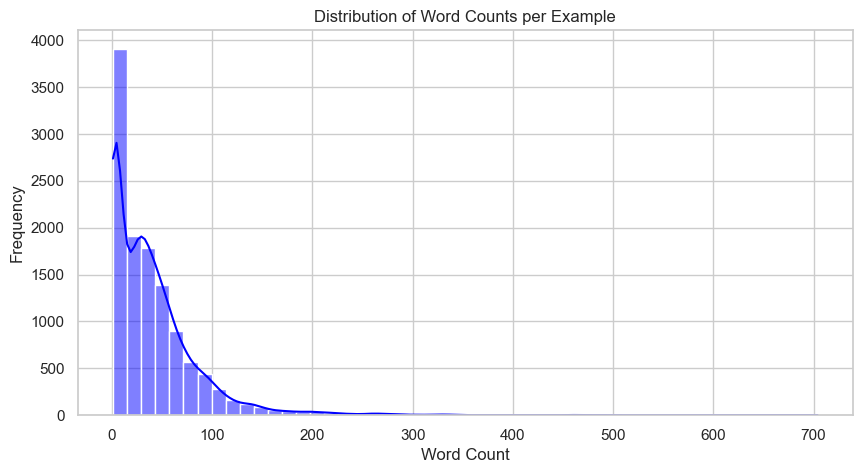

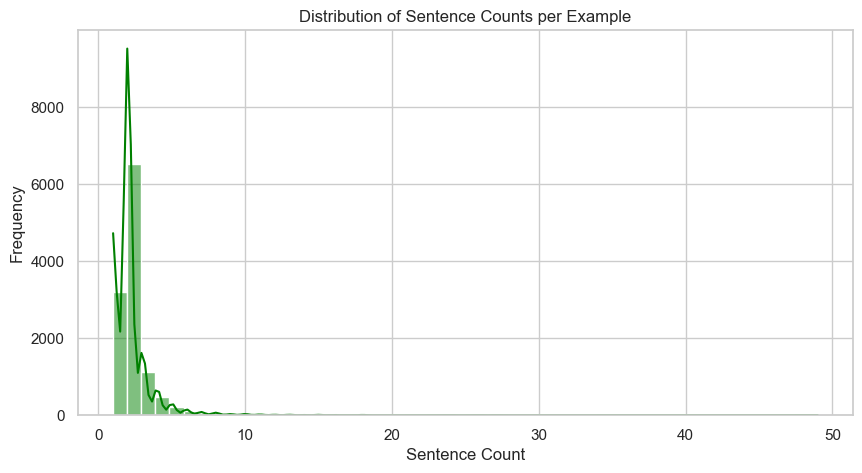

In [7]:
processed_df['char_count'] = processed_df['text'].apply(len)
processed_df['word_count'] = processed_df['text'].apply(lambda x: len(x.split()))
processed_df['sentence_count'] = processed_df['text'].apply(lambda x: len(re.split(r'[.!?]+', x)))

print("Min text length (chars):", processed_df['char_count'].min())
print("Max text length (chars):", processed_df['char_count'].max())
print("Mean text length (chars):", processed_df['char_count'].mean())
print("Median text length (chars):", processed_df['char_count'].median())
print("Average word count:", processed_df['word_count'].mean())
print("Average sentence count:", processed_df['sentence_count'].mean())

plt.figure(figsize=(10, 5))
sns.histplot(processed_df['word_count'], bins=50, kde=True, color='blue')
plt.title("Distribution of Word Counts per Example")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(10, 5))
sns.histplot(processed_df['sentence_count'], bins=50, kde=True, color='green')
plt.title("Distribution of Sentence Counts per Example")
plt.xlabel("Sentence Count")
plt.ylabel("Frequency")
plt.show()


### 9.3 Clause Frequency
Some clauses occur much more frequently than others. This creates class imbalance. For this reason, accuracy alone is not enough to judge the model.


,Clause,Positive Samples
0,parties,2554
1,license_grant,716
8,cap_on_liability,632
6,audit_rights,613
5,anti_assignment,612
28,insurance,531
7,document_name,521
11,agreement_date,475
17,governing_law,457
16,expiration_date,456


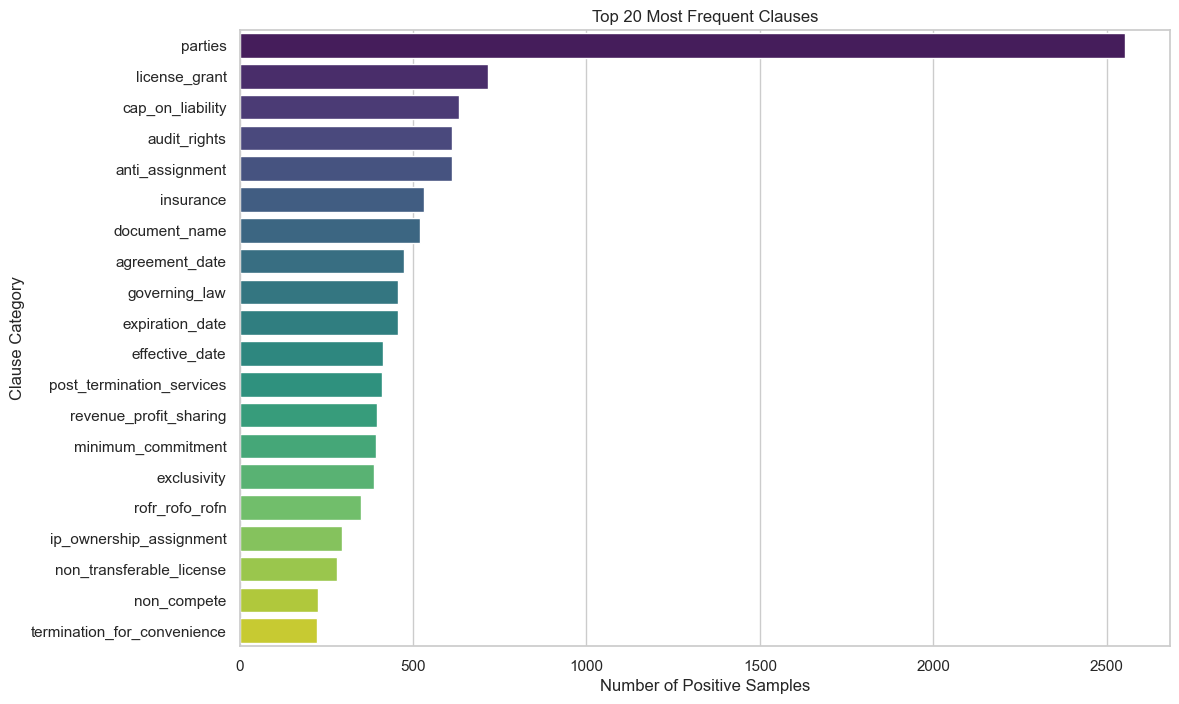

Clauses with zero positive examples: 0


In [8]:
from collections import Counter
clause_counts = Counter(all_labels)

freq_df = pd.DataFrame(clause_counts.items(), columns=["Clause", "Positive Samples"]).sort_values("Positive Samples", ascending=False)
display(freq_df.head(10))

plt.figure(figsize=(12, 8))
sns.barplot(x="Positive Samples", y="Clause", data=freq_df.head(20), palette="viridis")
plt.title("Top 20 Most Frequent Clauses")
plt.xlabel("Number of Positive Samples")
plt.ylabel("Clause Category")
plt.show()

print("Clauses with zero positive examples:", len([k for k,v in clause_counts.items() if v == 0]))


### 9.4 Positive and Negative Distribution
Since this is multi-label classification, each clause is treated as a separate binary prediction task. Most examples will be negative for any given clause.


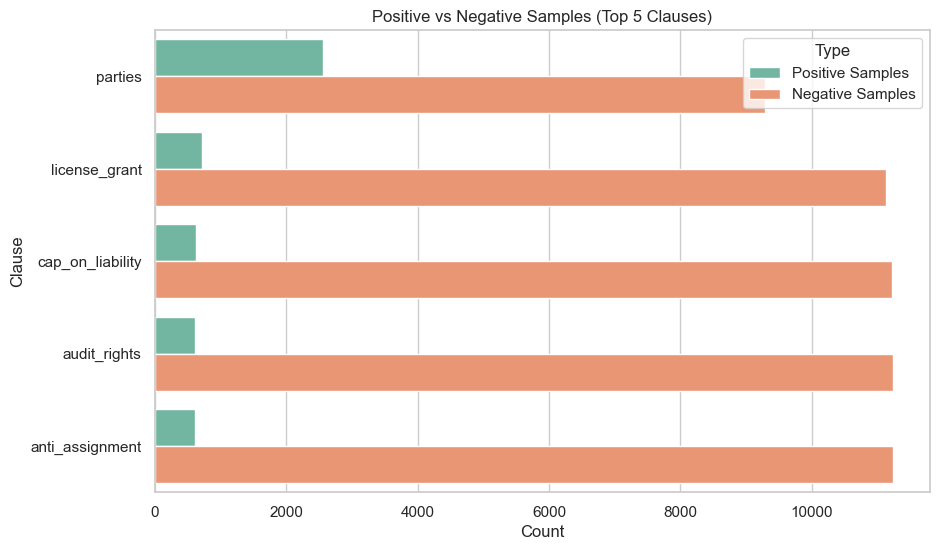

In [9]:
total_examples = len(processed_df)
freq_df['Negative Samples'] = total_examples - freq_df['Positive Samples']

# Plot top 5 for illustration
top_5_freq = freq_df.head(5).copy()
top_5_melted = top_5_freq.melt(id_vars='Clause', value_vars=['Positive Samples', 'Negative Samples'], var_name='Type', value_name='Count')

plt.figure(figsize=(10, 6))
sns.barplot(x='Count', y='Clause', hue='Type', data=top_5_melted, palette="Set2")
plt.title("Positive vs Negative Samples (Top 5 Clauses)")
plt.xlabel("Count")
plt.ylabel("Clause")
plt.show()


### 9.5 Average Labels per Example
A single contract passage can contain more than one clause category. This is why the project uses multi-label classification.


Average labels per example: 1.1055696202531646
Maximum labels per example: 5


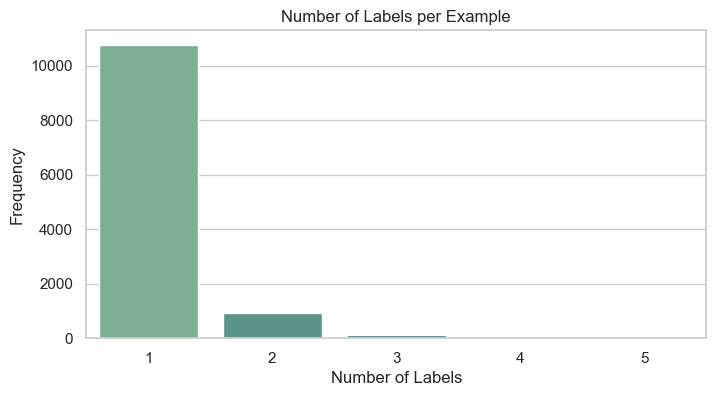

In [10]:
processed_df['label_count'] = processed_df['labels'].apply(len)
print("Average labels per example:", processed_df['label_count'].mean())
print("Maximum labels per example:", processed_df['label_count'].max())

plt.figure(figsize=(8, 4))
sns.countplot(x='label_count', data=processed_df, palette="crest")
plt.title("Number of Labels per Example")
plt.xlabel("Number of Labels")
plt.ylabel("Frequency")
plt.show()


## 10. Clause Co-Occurrence Analysis
This analysis shows which contractual clauses tend to appear in the same text examples. A high value means that the two clauses frequently occur together. (Note: this is not legal causation, just statistical co-occurrence).


,Clause A,Clause B,Co-occurrence Count
2,agreement_date,effective_date,223
3,license_grant,non_transferable_license,174
6,irrevocable_or_perpetual_license,license_grant,116
1,cap_on_liability,uncapped_liability,110
0,notice_period_to_terminate_renewal,renewal_term,93
4,exclusivity,license_grant,84
31,affiliate_license_licensee,license_grant,51
30,expiration_date,renewal_term,39
5,effective_date,expiration_date,37
35,affiliate_license_licensee,irrevocable_or_perpetual_license,29


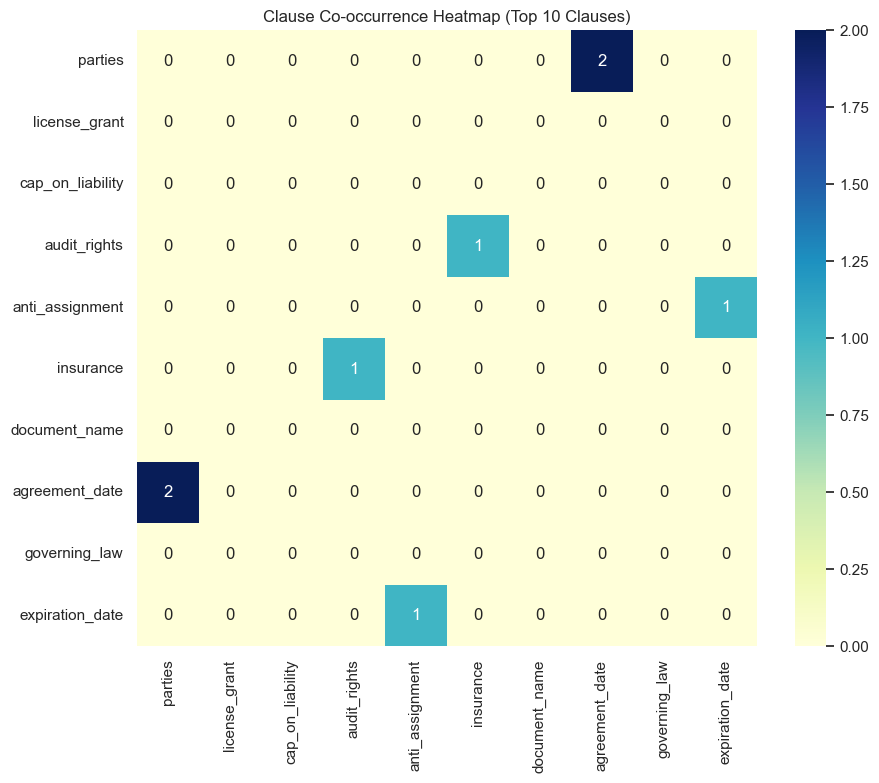

In [11]:
cooc = Counter()
for labels in processed_df['labels']:
    if len(labels) > 1:
        # Generate all pairs
        for pair in combinations(sorted(labels), 2):
            cooc[pair] += 1

cooc_df = pd.DataFrame([
    {"Clause A": pair[0], "Clause B": pair[1], "Co-occurrence Count": count}
    for pair, count in cooc.items()
]).sort_values("Co-occurrence Count", ascending=False)

display(cooc_df.head(10))

# Heatmap for top 10 most common clauses
top_10_clauses = freq_df['Clause'].head(10).tolist()
heatmap_data = pd.DataFrame(0, index=top_10_clauses, columns=top_10_clauses)

for _, row in cooc_df.iterrows():
    c1, c2, count = row['Clause A'], row['Clause B'], row['Co-occurrence Count']
    if c1 in top_10_clauses and c2 in top_10_clauses:
        heatmap_data.at[c1, c2] = count
        heatmap_data.at[c2, c1] = count

plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Clause Co-occurrence Heatmap (Top 10 Clauses)")
plt.show()


## 11. Text Preprocessing
Legal language is sensitive to small words. Words such as “not,” “unless,” and “except” can reverse or limit the meaning of a sentence. Therefore, preprocessing should be careful and should not remove important legal terms.


In [12]:
def preprocess_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    # Normalize whitespace
    text = re.sub(r'\s+', ' ', text)
    # Remove extremely weird non-ascii chars but keep punctuation
    text = text.encode('ascii', 'ignore').decode('ascii')
    return text.strip()

processed_df['clean_text'] = processed_df['text'].apply(preprocess_text)


## 12. Train/Test Split by Contract
We split by contract instead of only splitting by row. This prevents text from the same contract appearing in both training and testing data, which would make the evaluation unrealistically optimistic.


In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

# Generate indices
train_idx, test_idx = next(gss.split(processed_df, groups=processed_df['document_id']))

train_df = processed_df.iloc[train_idx]
test_df = processed_df.iloc[test_idx]

train_document_ids = train_df['document_id'].unique()
test_document_ids = test_df['document_id'].unique()

print("Training rows:", len(train_df))
print("Testing rows:", len(test_df))
print("Training documents:", len(train_document_ids))
print("Testing documents:", len(test_document_ids))

# Validation check
assert len(set(train_document_ids).intersection(set(test_document_ids))) == 0
print("Validation passed: No document overlap between train and test sets.")


Training rows: 9450
Testing rows: 2400
Training documents: 408
Testing documents: 102
Validation passed: No document overlap between train and test sets.


## 13. Multi-Label Target Preparation

In [14]:
mlb = MultiLabelBinarizer()

# Fit only on training labels
y_train = mlb.fit_transform(train_df['labels'])
# Transform test labels (any unseen labels in test set will be ignored safely)
y_test = mlb.transform(test_df['labels'])

print("Target matrix shape (Train):", y_train.shape)
print("Target matrix shape (Test):", y_test.shape)
print("\nClause Category Names (Classes):")
print(mlb.classes_[:10], "... (Showing first 10)")

print("\nSample Target Row (Binary Vector):")
print(y_train[0])


Target matrix shape (Train): (9450, 41)
Target matrix shape (Test): (2400, 41)

Clause Category Names (Classes):
['affiliate_license_licensee' 'affiliate_license_licensor'
 'agreement_date' 'anti_assignment' 'audit_rights' 'cap_on_liability'
 'change_of_control' 'competitive_restriction_exception'
 'covenant_not_to_sue' 'document_name'] ... (Showing first 10)

Sample Target Row (Binary Vector):
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0
 0 0 0 0]


## 14. TF-IDF Feature Extraction
TF-IDF converts text into numbers that machine-learning models can use. Unigrams are individual words, while bigrams are two-word phrases. Bigrams are useful because phrases such as “written notice” and “intellectual property” can carry important meaning.


In [15]:
vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(train_df['clean_text'])
X_test = vectorizer.transform(test_df['clean_text'])

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Number of vocabulary terms:", len(vectorizer.vocabulary_))

print("\nSample vocabulary examples:")
vocab_items = list(vectorizer.vocabulary_.items())[:5]
print(vocab_items)


Training feature shape: (9450, 37148)
Testing feature shape: (2400, 37148)
Number of vocabulary terms: 37148

Sample vocabulary examples:
[('provider', 26176), ('ability', 708), ('computer', 8053), ('software', 29509), ('industries', 15989)]


## 15. Train the Three Required Models
We train three different baseline models because different algorithms may perform differently on legal text. Comparing them helps us select the strongest model for this dataset.


In [16]:
models = {
    "Logistic Regression": OneVsRestClassifier(LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Linear SVM": OneVsRestClassifier(LinearSVC(class_weight="balanced", dual=False)),
    "Naive Bayes": OneVsRestClassifier(MultinomialNB())
}

trained_models = {}
training_times = {}

for name, model in models.items():
    print(f"Training {name}...")
    start_time = time.time()
    model.fit(X_train, y_train)
    end_time = time.time()
    
    trained_models[name] = model
    training_times[name] = end_time - start_time
    print(f"{name} trained in {training_times[name]:.2f} seconds.")


Training Logistic Regression...


Logistic Regression trained in 2.84 seconds.
Training Linear SVM...


Linear SVM trained in 6.06 seconds.
Training Naive Bayes...
Naive Bayes trained in 0.12 seconds.


## 16. Model Prediction and Score Handling

In [17]:
predictions = {}
scores = {}
prediction_times = {}

for name, model in trained_models.items():
    start_time = time.time()
    y_pred = model.predict(X_test)
    end_time = time.time()
    
    predictions[name] = y_pred
    prediction_times[name] = end_time - start_time
    
    # Safely get decision scores or probabilities
    if hasattr(model, "predict_proba"):
        scores[name] = model.predict_proba(X_test)
    elif hasattr(model, "decision_function"):
        scores[name] = model.decision_function(X_test)
    else:
        scores[name] = y_pred # Fallback


## 17. Model Evaluation
Macro F1 gives equal importance to every clause. This is useful when some clauses are rare because a model should not appear strong only by predicting common clauses correctly.


In [18]:
results = []

for name in trained_models.keys():
    y_pred = predictions[name]
    
    precision_macro = precision_score(y_test, y_pred, average="macro", zero_division=0)
    recall_macro = recall_score(y_test, y_pred, average="macro", zero_division=0)
    f1_macro = f1_score(y_test, y_pred, average="macro", zero_division=0)
    
    precision_micro = precision_score(y_test, y_pred, average="micro", zero_division=0)
    recall_micro = recall_score(y_test, y_pred, average="micro", zero_division=0)
    f1_micro = f1_score(y_test, y_pred, average="micro", zero_division=0)
    
    hamming = hamming_loss(y_test, y_pred)
    exact_match = accuracy_score(y_test, y_pred)
    
    results.append({
        "Model": name,
        "Precision": precision_macro,
        "Recall": recall_macro,
        "Macro F1": f1_macro,
        "Micro F1": f1_micro,
        "Hamming Loss": hamming,
        "Exact Match Ratio": exact_match,
        "Training Time": training_times[name]
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))


,Model,Precision,Recall,Macro F1,Micro F1,Hamming Loss,Exact Match Ratio,Training Time
0,Logistic Regression,0.6334,0.7580,0.6685,0.7858,0.0131,0.6346,2.8361
1,Linear SVM,0.8376,0.6681,0.7126,0.8496,0.0079,0.7367,6.0590
2,Naive Bayes,0.2618,0.0793,0.1104,0.3351,0.0217,0.2067,0.1212


## 18. Per-Clause Evaluation
Per-clause evaluation shows that performance can vary between clause categories. Rare clauses are often harder to learn because the model has fewer examples from which to learn their language patterns.


In [19]:
# Find best model based on Macro F1
best_model_name = results_df.loc[results_df['Macro F1'].idxmax(), 'Model']
print(f"Selected Model for Per-Clause Evaluation: {best_model_name}")

best_y_pred = predictions[best_model_name]

clause_metrics = []
for i, clause in enumerate(mlb.classes_):
    y_true_col = y_test[:, i]
    y_pred_col = best_y_pred[:, i]
    
    pos_samples = y_true_col.sum()
    prec = precision_score(y_true_col, y_pred_col, zero_division=0)
    rec = recall_score(y_true_col, y_pred_col, zero_division=0)
    f1 = f1_score(y_true_col, y_pred_col, zero_division=0)
    
    clause_metrics.append({
        "Clause": clause,
        "Positive Samples": pos_samples,
        "Precision": prec,
        "Recall": rec,
        "F1": f1
    })

clause_df = pd.DataFrame(clause_metrics).sort_values("F1", ascending=False)
display(clause_df.head(10))
print("\nWorst performing clauses:")
display(clause_df.tail(10))


Selected Model for Per-Clause Evaluation: Linear SVM


,Clause,Positive Samples,Precision,Recall,F1
9,document_name,106,0.990476,0.981132,0.985782
28,parties,507,0.982283,0.984221,0.983251
13,governing_law,88,1.000000,0.965909,0.982659
14,insurance,126,0.991228,0.896825,0.941667
4,audit_rights,85,0.974026,0.882353,0.925926
5,cap_on_liability,118,0.915966,0.923729,0.919831
2,agreement_date,95,0.846847,0.989474,0.912621
23,no_solicit_of_employees,25,0.954545,0.840000,0.893617
12,expiration_date,87,0.886364,0.896552,0.891429
3,anti_assignment,116,0.916667,0.853448,0.883929



Worst performing clauses:


,Clause,Positive Samples,Precision,Recall,F1
22,no_solicit_of_customers,9,1.000000,0.444444,0.615385
11,exclusivity,90,0.741935,0.511111,0.605263
19,liquidated_damages,21,0.692308,0.428571,0.529412
0,affiliate_license_licensee,28,0.785714,0.392857,0.523810
25,non_disparagement,11,0.666667,0.363636,0.470588
21,most_favored_nation,10,1.000000,0.200000,0.333333
1,affiliate_license_licensor,12,0.500000,0.250000,0.333333
38,unlimited_all_you_can_eat_license,9,1.000000,0.111111,0.200000
7,competitive_restriction_exception,20,1.000000,0.050000,0.095238
30,price_restrictions,3,0.000000,0.000000,0.000000


## 19. Best Model Selection
> **Warning**: The selected model is the best baseline model according to the current test split. Its performance may change on a different dataset or split.


In [20]:
best_model = trained_models[best_model_name]
best_predictions = best_y_pred
best_scores = scores[best_model_name]

best_row = results_df[results_df['Model'] == best_model_name].iloc[0]
print(f"Best Model Name: {best_model_name}")
print(f"Macro F1: {best_row['Macro F1']:.4f}")
print(f"Micro F1: {best_row['Micro F1']:.4f}")
print(f"Hamming Loss: {best_row['Hamming Loss']:.4f}")
print(f"Explanation: {best_model_name} was selected because it achieved the highest Macro F1 score across all tested baseline models on this dataset split.")


Best Model Name: Linear SVM
Macro F1: 0.7126
Micro F1: 0.8496
Hamming Loss: 0.0079
Explanation: Linear SVM was selected because it achieved the highest Macro F1 score across all tested baseline models on this dataset split.


## 20. Risk Analysis Design
The risk score is a project-specific heuristic designed to highlight potentially important contractual provisions. It is not legal advice and does not determine whether a contract is legally safe or unsafe.


In [21]:
risk_config = {
    "Non-Compete": {"weight": 3, "category": "High Risk"},
    "Exclusivity": {"weight": 3, "category": "High Risk"},
    "Termination For Convenience": {"weight": 2, "category": "Medium Risk"},
    "Indemnification": {"weight": 2, "category": "Medium Risk"},
    "Limitation Of Liability": {"weight": 2, "category": "Medium Risk"},
    "Audit Rights": {"weight": 2, "category": "Medium Risk"},
    "Renewal Term": {"weight": 1, "category": "Low Risk"},
    "Confidentiality": {"weight": 1, "category": "Low Risk"},
    "Governing Law": {"weight": 0, "category": "Informational"}
}

def calculate_risk(detected_clauses, config):
    total_score = 0
    contributions = []
    
    for clause in detected_clauses:
        # Fallback for unknown clauses
        details = config.get(clause, {"weight": 0, "category": "Informational"})
        weight = details["weight"]
        total_score += weight
        contributions.append({
            "Clause": clause,
            "Weight": f"+{weight}",
            "Category": details["category"]
        })
        
    if total_score >= 5:
        risk_level = "High"
    elif total_score >= 2:
        risk_level = "Medium"
    else:
        risk_level = "Low"
        
    return total_score, risk_level, contributions


## 21. Final Contract-Analysis Demonstration
This section demonstrates how the trained pipeline analyzes new legal text. The text is cleaned, converted into TF-IDF features, passed to the best model, converted into predicted clause names, and then used for the project-specific risk calculation.


In [22]:
# Select a real non-empty legal text example from the dataset with at least 1 known label
non_empty_examples = processed_df[
    processed_df["text"].notna() & 
    processed_df["text"].astype(str).str.strip().ne("") &
    (processed_df["labels"].apply(len) > 0)
].copy()

sample_row = non_empty_examples.iloc[10] # Grab an arbitrary row
sample_text = sample_row["text"]

# 1. Preprocess
clean_sample_text = preprocess_text(sample_text)

# 2. Extract TF-IDF features
sample_vector = vectorizer.transform([clean_sample_text])

# 3. Predict using the best model
predicted_binary = best_model.predict(sample_vector)
predicted_idx = np.where(predicted_binary[0] == 1)[0]
detected_clauses = [mlb.classes_[idx] for idx in predicted_idx]

# Safely extract scores for the detected classes
model_scores = {}
if hasattr(best_model, "predict_proba"):
    probs = best_model.predict_proba(sample_vector)[0]
    for idx in predicted_idx:
        model_scores[mlb.classes_[idx]] = probs[idx]
elif hasattr(best_model, "decision_function"):
    decs = best_model.decision_function(sample_vector)[0]
    for idx in predicted_idx:
        model_scores[mlb.classes_[idx]] = decs[idx]

# 4. Calculate Risk
total_score, risk_level, contributions = calculate_risk(detected_clauses, risk_config)

# 5. Display the output cleanly
print("==============================")
print("LEGAL CONTRACT ANALYSIS")
print("==============================\n")
print("Input Text (truncated to 500 chars):")
print(f'"{sample_text[:500]}..."\n')

print("Detected Clauses:")
if detected_clauses:
    for c in detected_clauses:
        print(f"✓ {c}")
else:
    print("- No clauses crossed the prediction threshold. The model may be uncertain about this text.")

print("\nModel Scores:")
for c, s in model_scores.items():
    print(f"{c}: {s:.2f}")

print("\nRisk Contributions:")
for contrib in contributions:
    print(f"{contrib['Clause']}: {contrib['Weight']}")

print("\nTotal Risk Score:")
print(total_score)

print("\nRisk Level:")
print(risk_level)


LEGAL CONTRACT ANALYSIS

Input Text (truncated to 500 chars):
"If a majority of the equity securities of either 2TheMart or i-Escrow, Inc. (except that i-Escrow may sell all or a majority of its equity securities or voting interests to i-Escrow.com, and i-Escrow.com may sell all or a majority of its equity securities or voting interests to i-Escrow's existing shareholders, without triggering the foregoing) are acquired by another company during the term of this Agreement either company may terminate this Agreement, without liability, by giving a thirty (30)..."

Detected Clauses:
- No clauses crossed the prediction threshold. The model may be uncertain about this text.

Model Scores:

Risk Contributions:

Total Risk Score:
0

Risk Level:
Low


## 23. Model Saving
These files allow the trained system to be reused later without retraining the model from the beginning.


In [23]:
MODEL_DIR = "saved_models"
os.makedirs(MODEL_DIR, exist_ok=True)

joblib.dump(best_model, os.path.join(MODEL_DIR, "best_clause_model.joblib"))
joblib.dump(vectorizer, os.path.join(MODEL_DIR, "tfidf_vectorizer.joblib"))
joblib.dump(mlb.classes_, os.path.join(MODEL_DIR, "clause_categories.joblib"))
joblib.dump(risk_config, os.path.join(MODEL_DIR, "risk_config.joblib"))

print("Models and configuration saved successfully to 'saved_models/' directory.")

# Verify files exist
for f in ["best_clause_model.joblib", "tfidf_vectorizer.joblib", "clause_categories.joblib", "risk_config.joblib"]:
    if os.path.exists(os.path.join(MODEL_DIR, f)):
        print(f"✓ {f} exists")


Models and configuration saved successfully to 'saved_models/' directory.
✓ best_clause_model.joblib exists
✓ tfidf_vectorizer.joblib exists
✓ clause_categories.joblib exists
✓ risk_config.joblib exists


## 24. Optional Summarization
*Note: Contract summarization via generative AI or extractive techniques is beyond the scope of this baseline NLP pipeline. It is noted as Future Work.*


## 25. Conclusion

### What We Did
* Loaded the CUAD dataset.
* Cleaned the legal text.
* Converted the data into a multi-label format.
* Performed EDA.
* Analyzed text length and clause frequency.
* Checked clause co-occurrence.
* Used group-based splitting by contract.
* Converted text into TF-IDF features.
* Trained three machine-learning models.
* Compared the models.
* Evaluated each clause.
* Selected the best model.
* Demonstrated real-text inference.
* Calculated a heuristic risk score.
* Saved the trained objects.

### What the Model Does
The model receives legal contract text, converts it into numerical TF-IDF features, predicts one or more possible clause categories, and calculates a transparent project-specific risk score based on the detected clauses.

### Limitations
* The model may perform poorly on rare clauses.
* The model depends on the quality and coverage of the training data.
* TF-IDF does not fully understand legal meaning.
* The model may miss clauses written in unusual language.
* Model scores are not legal certainty.
* Risk categories are heuristic and not official legal standards.
* The system does not replace a lawyer.
* The system should not be used alone for legal decisions.
* The test results may not generalize to every contract type.

### Future Improvements
* Legal-BERT.
* Domain-specific transformer models.
* Larger and more diverse legal datasets.
* Better clause boundary detection.
* Calibrated confidence scores.
* Human review workflows.
* Extractive or neural summarization.
* Explainable AI methods.
* More advanced legal information extraction.
* Streamlit or API deployment as a separate future project.
